# Software Quality Insight

**Business Question:** Which software metrics are associated with modules having more defects?

### Step 1: Data Generation
In this step, we generate 5 synthetic datasets with embedded data-quality anomalies to simulate a real-world software project scenario for future cleaning.

In [1]:
import pandas as pd
import numpy as np

# Set seed for reproducibility
np.random.seed(42)

#### 1. Modules Dataset
Contains general information about each software module. Includes an inconsistent module name ('Mod_E' vs 'MOD_E') to clean later.

In [2]:
modules_data = {
    'module': ['MOD_A', 'MOD_B', 'MOD_C', 'MOD_D', 'Mod_E', 'MOD_F', 'MOD_G', 'MOD_H'],
    'component': ['UI', 'Backend', 'Database', 'API', 'UI', 'Backend', 'Database', 'API'],
    'language': ['JavaScript', 'Python', 'SQL', 'Python', 'JavaScript', 'Java', 'SQL', 'Java'],
    'size': [120, 450, 80, 300, 150, 600, 95, 250]
}
modules_df = pd.DataFrame(modules_data)

# Save to csv
modules_df.to_csv('modules.csv', index=False)

print("Shape of Modules:", modules_df.shape)
display(modules_df.head(10))

Shape of Modules: (8, 4)


,module,component,language,size
0,MOD_A,UI,JavaScript,120
1,MOD_B,Backend,Python,450
2,MOD_C,Database,SQL,80
3,MOD_D,API,Python,300
4,Mod_E,UI,JavaScript,150
5,MOD_F,Backend,Java,600
6,MOD_G,Database,SQL,95
7,MOD_H,API,Java,250


#### 2. Metrics Dataset
Contains code metrics. Includes an extreme outlier for complexity (999) and a few missing values (NaN) in test coverage.

In [3]:
metrics_data = {
    'module': ['MOD_A', 'MOD_B', 'MOD_C', 'MOD_D', 'MOD_E', 'MOD_F', 'MOD_G', 'MOD_H'],
    'complexity': [12, 45, 999, 28, 15, 55, 10, 22], # MOD_C has extreme complexity
    'coupling': [5, 12, 3, 8, 6, 15, 2, 7],
    'churn': [80, 210, 15, 130, 95, 300, 20, 110],
    'test_coverage': [85.0, 60.0, np.nan, 75.0, 90.0, np.nan, 95.0, 80.0] # missing values
}
metrics_df = pd.DataFrame(metrics_data)

# Save to csv
metrics_df.to_csv('metrics.csv', index=False)

print("Shape of Metrics:", metrics_df.shape)
display(metrics_df.head(10))

Shape of Metrics: (8, 5)


,module,complexity,coupling,churn,test_coverage
0,MOD_A,12,5,80,85.0
1,MOD_B,45,12,210,60.0
2,MOD_C,999,3,15,NaN
3,MOD_D,28,8,130,75.0
4,MOD_E,15,6,95,90.0
5,MOD_F,55,15,300,NaN
6,MOD_G,10,2,20,95.0
7,MOD_H,22,7,110,80.0


#### 3. Defects Dataset
Contains logged defects. Includes a duplicate record for MOD_A and an unmatched module ('MOD_XYZ') which does not exist in modules.csv.

In [4]:
defects_data = {
    'module': ['MOD_A', 'MOD_A', 'MOD_B', 'MOD_C', 'MOD_D', 'MOD_E', 'MOD_F', 'MOD_XYZ'], # MOD_A is duplicate, MOD_XYZ is unmatched
    'defect_count': [2, 2, 8, 1, 4, 3, 12, 5],
    'severity': ['Low', 'Low', 'High', 'Low', 'Medium', 'Medium', 'High', 'High'],
    'release': ['v1.0', 'v1.0', 'v1.0', 'v1.1', 'v1.1', 'v1.0', 'v1.1', 'v1.1']
}
defects_df = pd.DataFrame(defects_data)

# Save to csv
defects_df.to_csv('defects.csv', index=False)

print("Shape of Defects:", defects_df.shape)
display(defects_df.head(10))

Shape of Defects: (8, 4)


,module,defect_count,severity,release
0,MOD_A,2,Low,v1.0
1,MOD_A,2,Low,v1.0
2,MOD_B,8,High,v1.0
3,MOD_C,1,Low,v1.1
4,MOD_D,4,Medium,v1.1
5,MOD_E,3,Medium,v1.0
6,MOD_F,12,High,v1.1
7,MOD_XYZ,5,High,v1.1


#### 4. Commits Dataset
Contains git statistics for each module.

In [5]:
commits_data = {
    'module': ['MOD_A', 'MOD_B', 'MOD_C', 'MOD_D', 'MOD_E', 'MOD_F', 'MOD_G', 'MOD_H'],
    'commit_count': [15, 45, 8, 28, 22, 60, 5, 18],
    'contributors': [2, 5, 1, 3, 2, 6, 1, 2],
    'changed_lines': [1500, 6200, 450, 3100, 1800, 8500, 300, 2100]
}
commits_df = pd.DataFrame(commits_data)

# Save to csv
commits_df.to_csv('commits.csv', index=False)

print("Shape of Commits:", commits_df.shape)
display(commits_df.head(10))

Shape of Commits: (8, 4)


,module,commit_count,contributors,changed_lines
0,MOD_A,15,2,1500
1,MOD_B,45,5,6200
2,MOD_C,8,1,450
3,MOD_D,28,3,3100
4,MOD_E,22,2,1800
5,MOD_F,60,6,8500
6,MOD_G,5,1,300
7,MOD_H,18,2,2100


#### 5. Releases Dataset
Contains release mapping details.

In [6]:
releases_data = {
    'release_date': ['2023-01-15', '2023-01-15', '2023-06-01', '2023-01-15', '2023-06-01'],
    'version': ['v1.0', 'v1.0', 'v1.1', 'v1.0', 'v1.1'],
    'module': ['MOD_A', 'MOD_B', 'MOD_C', 'MOD_E', 'MOD_F']
}
releases_df = pd.DataFrame(releases_data)

# Save to csv
releases_df.to_csv('releases.csv', index=False)

print("Shape of Releases:", releases_df.shape)
display(releases_df.head(10))

Shape of Releases: (5, 3)


,release_date,version,module
0,2023-01-15,v1.0,MOD_A
1,2023-01-15,v1.0,MOD_B
2,2023-06-01,v1.1,MOD_C
3,2023-01-15,v1.0,MOD_E
4,2023-06-01,v1.1,MOD_F


### Step 2: Data Cleaning and Preprocessing
In this step, we will clean our synthetic datasets to fix structural issues, missing values, duplicates, and outliers before conducting our analysis.

#### 1. Standardize Module Casing
We convert all module names in `modules_df` to uppercase so that 'Mod_E' consistently matches 'MOD_E' across other datasets.

In [7]:
print("Before cleaning:")
print(modules_df['module'].unique())

# Convert module column to uppercase
modules_df['module'] = modules_df['module'].str.upper()

print("\nAfter cleaning:")
print(modules_df['module'].unique())

Before cleaning:
['MOD_A' 'MOD_B' 'MOD_C' 'MOD_D' 'Mod_E' 'MOD_F' 'MOD_G' 'MOD_H']

After cleaning:
['MOD_A' 'MOD_B' 'MOD_C' 'MOD_D' 'MOD_E' 'MOD_F' 'MOD_G' 'MOD_H']


#### 2. Handle Missing Values in Test Coverage
We will replace the missing values (`NaN`) in the `test_coverage` column of `metrics_df` with the average test coverage.

In [8]:
print("Missing values in metrics:")
print(metrics_df.isnull().sum())

# Calculate mean coverage
mean_coverage = metrics_df['test_coverage'].mean()

# Fill NaN with the mean value
metrics_df['test_coverage'] = metrics_df['test_coverage'].fillna(mean_coverage)

print("\nAfter imputation:")
print(metrics_df.isnull().sum())
display(metrics_df.head(10))

Missing values in metrics:
module           0
complexity       0
coupling         0
churn            0
test_coverage    2
dtype: int64

After imputation:
module           0
complexity       0
coupling         0
churn            0
test_coverage    0
dtype: int64


,module,complexity,coupling,churn,test_coverage
0,MOD_A,12,5,80,85.000000
1,MOD_B,45,12,210,60.000000
2,MOD_C,999,3,15,80.833333
3,MOD_D,28,8,130,75.000000
4,MOD_E,15,6,95,90.000000
5,MOD_F,55,15,300,80.833333
6,MOD_G,10,2,20,95.000000
7,MOD_H,22,7,110,80.000000


#### 3. Remove Duplicate Records
We will drop the exact duplicate row for `MOD_A` from `defects_df`.

In [9]:
print("Shape of defects before removing duplicates:", defects_df.shape)

# Drop duplicates
defects_df = defects_df.drop_duplicates()

print("Shape of defects after removing duplicates:", defects_df.shape)
display(defects_df.head(10))

Shape of defects before removing duplicates: (8, 4)
Shape of defects after removing duplicates: (7, 4)


,module,defect_count,severity,release
0,MOD_A,2,Low,v1.0
2,MOD_B,8,High,v1.0
3,MOD_C,1,Low,v1.1
4,MOD_D,4,Medium,v1.1
5,MOD_E,3,Medium,v1.0
6,MOD_F,12,High,v1.1
7,MOD_XYZ,5,High,v1.1


#### 4. Handle Extreme Complexity Value
We will replace the outlier complexity value of `999` with the median of the remaining valid complexities (values < 100).

In [10]:
print("Complexity values before replacement:")
print(metrics_df['complexity'].tolist())

# Calculate median excluding the outlier
median_complexity = metrics_df[metrics_df['complexity'] < 100]['complexity'].median()

# Replace outlier with the median
metrics_df.loc[metrics_df['complexity'] > 100, 'complexity'] = median_complexity

print("\nComplexity values after replacement:")
print(metrics_df['complexity'].tolist())

Complexity values before replacement:
[12, 45, 999, 28, 15, 55, 10, 22]

Complexity values after replacement:
[12, 45, 22, 28, 15, 55, 10, 22]


#### 5. Remove Unmatched Modules
We will remove records from `defects_df` that do not exist in our validated list of modules in `modules_df` (such as `MOD_XYZ`).

In [11]:
print("Defects before filtering:")
print(defects_df['module'].tolist())

# Keep only modules present in modules_df
defects_df = defects_df[defects_df['module'].isin(modules_df['module'])]

print("\nDefects after removing unmatched:")
print(defects_df['module'].tolist())
display(defects_df.head(10))

Defects before filtering:
['MOD_A', 'MOD_B', 'MOD_C', 'MOD_D', 'MOD_E', 'MOD_F', 'MOD_XYZ']

Defects after removing unmatched:
['MOD_A', 'MOD_B', 'MOD_C', 'MOD_D', 'MOD_E', 'MOD_F']


,module,defect_count,severity,release
0,MOD_A,2,Low,v1.0
2,MOD_B,8,High,v1.0
3,MOD_C,1,Low,v1.1
4,MOD_D,4,Medium,v1.1
5,MOD_E,3,Medium,v1.0
6,MOD_F,12,High,v1.1


### Step 2: Data Cleaning and Preprocessing
In this step, we will clean our synthetic datasets to fix structural issues, missing values, duplicates, and outliers before conducting our analysis.

#### 1. Standardize Module Casing
We convert all module names in `modules_df` to uppercase so that 'Mod_E' consistently matches 'MOD_E' across other datasets.

In [12]:
print("Before cleaning:")
print(modules_df['module'].unique())

# Convert module column to uppercase
modules_df['module'] = modules_df['module'].str.upper()

print("\nAfter cleaning:")
print(modules_df['module'].unique())

Before cleaning:
['MOD_A' 'MOD_B' 'MOD_C' 'MOD_D' 'MOD_E' 'MOD_F' 'MOD_G' 'MOD_H']

After cleaning:
['MOD_A' 'MOD_B' 'MOD_C' 'MOD_D' 'MOD_E' 'MOD_F' 'MOD_G' 'MOD_H']


#### 2. Handle Missing Values in Test Coverage
We will replace the missing values (`NaN`) in the `test_coverage` column of `metrics_df` with the average test coverage.

In [13]:
print("Missing values in metrics:")
print(metrics_df.isnull().sum())

# Calculate mean coverage
mean_coverage = metrics_df['test_coverage'].mean()

# Fill NaN with the mean value
metrics_df['test_coverage'] = metrics_df['test_coverage'].fillna(mean_coverage)

print("\nAfter imputation:")
print(metrics_df.isnull().sum())
display(metrics_df.head(10))

Missing values in metrics:
module           0
complexity       0
coupling         0
churn            0
test_coverage    0
dtype: int64

After imputation:
module           0
complexity       0
coupling         0
churn            0
test_coverage    0
dtype: int64


,module,complexity,coupling,churn,test_coverage
0,MOD_A,12,5,80,85.000000
1,MOD_B,45,12,210,60.000000
2,MOD_C,22,3,15,80.833333
3,MOD_D,28,8,130,75.000000
4,MOD_E,15,6,95,90.000000
5,MOD_F,55,15,300,80.833333
6,MOD_G,10,2,20,95.000000
7,MOD_H,22,7,110,80.000000


#### 3. Remove Duplicate Records
We will drop the exact duplicate row for `MOD_A` from `defects_df`.

In [14]:
print("Shape of defects before removing duplicates:", defects_df.shape)

# Drop duplicates
defects_df = defects_df.drop_duplicates()

print("Shape of defects after removing duplicates:", defects_df.shape)
display(defects_df.head(10))

Shape of defects before removing duplicates: (6, 4)
Shape of defects after removing duplicates: (6, 4)


,module,defect_count,severity,release
0,MOD_A,2,Low,v1.0
2,MOD_B,8,High,v1.0
3,MOD_C,1,Low,v1.1
4,MOD_D,4,Medium,v1.1
5,MOD_E,3,Medium,v1.0
6,MOD_F,12,High,v1.1


#### 4. Handle Extreme Complexity Value
We will replace the outlier complexity value of `999` with the median of the remaining valid complexities (values < 100).

In [15]:
print("Complexity values before replacement:")
print(metrics_df['complexity'].tolist())

# Calculate median excluding the outlier
median_complexity = metrics_df[metrics_df['complexity'] < 100]['complexity'].median()

# Replace outlier with the median
metrics_df.loc[metrics_df['complexity'] > 100, 'complexity'] = median_complexity

print("\nComplexity values after replacement:")
print(metrics_df['complexity'].tolist())

Complexity values before replacement:
[12, 45, 22, 28, 15, 55, 10, 22]

Complexity values after replacement:
[12, 45, 22, 28, 15, 55, 10, 22]


#### 5. Remove Unmatched Modules
We will remove records from `defects_df` that do not exist in our validated list of modules in `modules_df` (such as `MOD_XYZ`).

In [16]:
print("Defects before filtering:")
print(defects_df['module'].tolist())

# Keep only modules present in modules_df
defects_df = defects_df[defects_df['module'].isin(modules_df['module'])]

print("\nDefects after removing unmatched:")
print(defects_df['module'].tolist())
display(defects_df.head(10))

Defects before filtering:
['MOD_A', 'MOD_B', 'MOD_C', 'MOD_D', 'MOD_E', 'MOD_F']

Defects after removing unmatched:
['MOD_A', 'MOD_B', 'MOD_C', 'MOD_D', 'MOD_E', 'MOD_F']


,module,defect_count,severity,release
0,MOD_A,2,Low,v1.0
2,MOD_B,8,High,v1.0
3,MOD_C,1,Low,v1.1
4,MOD_D,4,Medium,v1.1
5,MOD_E,3,Medium,v1.0
6,MOD_F,12,High,v1.1


### Step 2: Data Cleaning and Preprocessing
In this step, we will clean our synthetic datasets to fix structural issues, missing values, duplicates, and outliers before conducting our analysis.

#### 1. Standardize Module Casing
We convert all module names in `modules_df` to uppercase so that 'Mod_E' consistently matches 'MOD_E' across other datasets.

In [17]:
print("Before cleaning:")
print(modules_df['module'].unique())

# Convert module column to uppercase
modules_df['module'] = modules_df['module'].str.upper()

print("\nAfter cleaning:")
print(modules_df['module'].unique())

Before cleaning:
['MOD_A' 'MOD_B' 'MOD_C' 'MOD_D' 'MOD_E' 'MOD_F' 'MOD_G' 'MOD_H']

After cleaning:
['MOD_A' 'MOD_B' 'MOD_C' 'MOD_D' 'MOD_E' 'MOD_F' 'MOD_G' 'MOD_H']


#### 2. Handle Missing Values in Test Coverage
We will replace the missing values (`NaN`) in the `test_coverage` column of `metrics_df` with the average test coverage.

In [18]:
print("Missing values in metrics:")
print(metrics_df.isnull().sum())

# Calculate mean coverage
mean_coverage = metrics_df['test_coverage'].mean()

# Fill NaN with the mean value
metrics_df['test_coverage'] = metrics_df['test_coverage'].fillna(mean_coverage)

print("\nAfter imputation:")
print(metrics_df.isnull().sum())
display(metrics_df.head(10))

Missing values in metrics:
module           0
complexity       0
coupling         0
churn            0
test_coverage    0
dtype: int64

After imputation:
module           0
complexity       0
coupling         0
churn            0
test_coverage    0
dtype: int64


,module,complexity,coupling,churn,test_coverage
0,MOD_A,12,5,80,85.000000
1,MOD_B,45,12,210,60.000000
2,MOD_C,22,3,15,80.833333
3,MOD_D,28,8,130,75.000000
4,MOD_E,15,6,95,90.000000
5,MOD_F,55,15,300,80.833333
6,MOD_G,10,2,20,95.000000
7,MOD_H,22,7,110,80.000000


#### 3. Remove Duplicate Records
We will drop the exact duplicate row for `MOD_A` from `defects_df`.

In [19]:
print("Shape of defects before removing duplicates:", defects_df.shape)

# Drop duplicates
defects_df = defects_df.drop_duplicates()

print("Shape of defects after removing duplicates:", defects_df.shape)
display(defects_df.head(10))

Shape of defects before removing duplicates: (6, 4)
Shape of defects after removing duplicates: (6, 4)


,module,defect_count,severity,release
0,MOD_A,2,Low,v1.0
2,MOD_B,8,High,v1.0
3,MOD_C,1,Low,v1.1
4,MOD_D,4,Medium,v1.1
5,MOD_E,3,Medium,v1.0
6,MOD_F,12,High,v1.1


#### 4. Handle Extreme Complexity Value
We will replace the outlier complexity value of `999` with the median of the remaining valid complexities (values < 100).

In [20]:
print("Complexity values before replacement:")
print(metrics_df['complexity'].tolist())

# Calculate median excluding the outlier
median_complexity = metrics_df[metrics_df['complexity'] < 100]['complexity'].median()

# Replace outlier with the median
metrics_df.loc[metrics_df['complexity'] > 100, 'complexity'] = median_complexity

print("\nComplexity values after replacement:")
print(metrics_df['complexity'].tolist())

Complexity values before replacement:
[12, 45, 22, 28, 15, 55, 10, 22]

Complexity values after replacement:
[12, 45, 22, 28, 15, 55, 10, 22]


#### 5. Remove Unmatched Modules
We will remove records from `defects_df` that do not exist in our validated list of modules in `modules_df` (such as `MOD_XYZ`).

In [21]:
print("Defects before filtering:")
print(defects_df['module'].tolist())

# Keep only modules present in modules_df
defects_df = defects_df[defects_df['module'].isin(modules_df['module'])]

print("\nDefects after removing unmatched:")
print(defects_df['module'].tolist())
display(defects_df.head(10))

Defects before filtering:
['MOD_A', 'MOD_B', 'MOD_C', 'MOD_D', 'MOD_E', 'MOD_F']

Defects after removing unmatched:
['MOD_A', 'MOD_B', 'MOD_C', 'MOD_D', 'MOD_E', 'MOD_F']


,module,defect_count,severity,release
0,MOD_A,2,Low,v1.0
2,MOD_B,8,High,v1.0
3,MOD_C,1,Low,v1.1
4,MOD_D,4,Medium,v1.1
5,MOD_E,3,Medium,v1.0
6,MOD_F,12,High,v1.1


### Step 3: Merging the Cleaned Datasets
To analyze the relationship between software metrics and defect counts, we will merge the `modules_df`, `metrics_df`, `defects_df`, and `commits_df` datasets together on the common `module` key.

In [32]:
# Merge modules with metrics
merged_df = pd.merge(modules_df, metrics_df, on='module', how='inner')

# Merge with defects
merged_df = pd.merge(merged_df, defects_df, on='module', how='inner')

# Merge with commits
merged_df = pd.merge(merged_df, commits_df, on='module', how='inner')

print("Final Merged Dataset Shape:", merged_df.shape)
display(merged_df)

Final Merged Dataset Shape: (6, 14)


,module,component,language,size,complexity,coupling,churn,test_coverage,defect_count,severity,release,commit_count,contributors,changed_lines
0,MOD_A,UI,JavaScript,120,12,5,80,85.000000,2,Low,v1.0,15,2,1500
1,MOD_B,Backend,Python,450,45,12,210,60.000000,8,High,v1.0,45,5,6200
2,MOD_C,Database,SQL,80,22,3,15,80.833333,1,Low,v1.1,8,1,450
3,MOD_D,API,Python,300,28,8,130,75.000000,4,Medium,v1.1,28,3,3100
4,MOD_E,UI,JavaScript,150,15,6,95,90.000000,3,Medium,v1.0,22,2,1800
5,MOD_F,Backend,Java,600,55,15,300,80.833333,12,High,v1.1,60,6,8500


### Step 3: Merging the Cleaned Datasets
To analyze the relationship between software metrics and defect counts, we will merge the `modules_df`, `metrics_df`, `defects_df`, and `commits_df` datasets together on the common `module` key.

In [33]:
# Merge modules with metrics
merged_df = pd.merge(modules_df, metrics_df, on='module', how='inner')

# Merge with defects
merged_df = pd.merge(merged_df, defects_df, on='module', how='inner')

# Merge with commits
merged_df = pd.merge(merged_df, commits_df, on='module', how='inner')

print("Final Merged Dataset Shape:", merged_df.shape)
display(merged_df)

Final Merged Dataset Shape: (6, 14)


,module,component,language,size,complexity,coupling,churn,test_coverage,defect_count,severity,release,commit_count,contributors,changed_lines
0,MOD_A,UI,JavaScript,120,12,5,80,85.000000,2,Low,v1.0,15,2,1500
1,MOD_B,Backend,Python,450,45,12,210,60.000000,8,High,v1.0,45,5,6200
2,MOD_C,Database,SQL,80,22,3,15,80.833333,1,Low,v1.1,8,1,450
3,MOD_D,API,Python,300,28,8,130,75.000000,4,Medium,v1.1,28,3,3100
4,MOD_E,UI,JavaScript,150,15,6,95,90.000000,3,Medium,v1.0,22,2,1800
5,MOD_F,Backend,Java,600,55,15,300,80.833333,12,High,v1.1,60,6,8500


### Step 3: Merging the Cleaned Datasets
To analyze the relationship between software metrics and defect counts, we will merge the `modules_df`, `metrics_df`, `defects_df`, and `commits_df` datasets together on the common `module` key.

In [34]:
# Merge modules with metrics
merged_df = pd.merge(modules_df, metrics_df, on='module', how='inner')

# Merge with defects
merged_df = pd.merge(merged_df, defects_df, on='module', how='inner')

# Merge with commits
merged_df = pd.merge(merged_df, commits_df, on='module', how='inner')

print("Final Merged Dataset Shape:", merged_df.shape)
display(merged_df)

Final Merged Dataset Shape: (6, 14)


,module,component,language,size,complexity,coupling,churn,test_coverage,defect_count,severity,release,commit_count,contributors,changed_lines
0,MOD_A,UI,JavaScript,120,12,5,80,85.000000,2,Low,v1.0,15,2,1500
1,MOD_B,Backend,Python,450,45,12,210,60.000000,8,High,v1.0,45,5,6200
2,MOD_C,Database,SQL,80,22,3,15,80.833333,1,Low,v1.1,8,1,450
3,MOD_D,API,Python,300,28,8,130,75.000000,4,Medium,v1.1,28,3,3100
4,MOD_E,UI,JavaScript,150,15,6,95,90.000000,3,Medium,v1.0,22,2,1800
5,MOD_F,Backend,Java,600,55,15,300,80.833333,12,High,v1.1,60,6,8500


### Step 3: Merging the Cleaned Datasets
To analyze the relationship between software metrics and defect counts, we will merge the `modules_df`, `metrics_df`, `defects_df`, and `commits_df` datasets together on the common `module` key.

In [35]:
# Merge modules with metrics
merged_df = pd.merge(modules_df, metrics_df, on='module', how='inner')

# Merge with defects
merged_df = pd.merge(merged_df, defects_df, on='module', how='inner')

# Merge with commits
merged_df = pd.merge(merged_df, commits_df, on='module', how='inner')

print("Final Merged Dataset Shape:", merged_df.shape)
display(merged_df)

Final Merged Dataset Shape: (6, 14)


,module,component,language,size,complexity,coupling,churn,test_coverage,defect_count,severity,release,commit_count,contributors,changed_lines
0,MOD_A,UI,JavaScript,120,12,5,80,85.000000,2,Low,v1.0,15,2,1500
1,MOD_B,Backend,Python,450,45,12,210,60.000000,8,High,v1.0,45,5,6200
2,MOD_C,Database,SQL,80,22,3,15,80.833333,1,Low,v1.1,8,1,450
3,MOD_D,API,Python,300,28,8,130,75.000000,4,Medium,v1.1,28,3,3100
4,MOD_E,UI,JavaScript,150,15,6,95,90.000000,3,Medium,v1.0,22,2,1800
5,MOD_F,Backend,Java,600,55,15,300,80.833333,12,High,v1.1,60,6,8500


### Step 3: Merging the Cleaned Datasets
To analyze the relationship between software metrics and defect counts, we will merge our cleaned `modules_df`, `metrics_df`, `defects_df`, and `commits_df` datasets together on the common `module` key.

In [36]:
# Merge modules with metrics
merged_df = pd.merge(modules_df, metrics_df, on='module', how='inner')

# Merge with defects
merged_df = pd.merge(merged_df, defects_df, on='module', how='inner')

# Merge with commits
merged_df = pd.merge(merged_df, commits_df, on='module', how='inner')

print("Final Merged Dataset Shape:", merged_df.shape)
display(merged_df)

Final Merged Dataset Shape: (6, 14)


,module,component,language,size,complexity,coupling,churn,test_coverage,defect_count,severity,release,commit_count,contributors,changed_lines
0,MOD_A,UI,JavaScript,120,12,5,80,85.000000,2,Low,v1.0,15,2,1500
1,MOD_B,Backend,Python,450,45,12,210,60.000000,8,High,v1.0,45,5,6200
2,MOD_C,Database,SQL,80,22,3,15,80.833333,1,Low,v1.1,8,1,450
3,MOD_D,API,Python,300,28,8,130,75.000000,4,Medium,v1.1,28,3,3100
4,MOD_E,UI,JavaScript,150,15,6,95,90.000000,3,Medium,v1.0,22,2,1800
5,MOD_F,Backend,Java,600,55,15,300,80.833333,12,High,v1.1,60,6,8500


### Step 3: Merging the Cleaned Datasets
Now that our tables are clean, we will perform a sequential inner join on the common `'module'` key to compile our master dataset for analysis.

In [37]:
# Merge modules with metrics
merged_df = pd.merge(modules_df, metrics_df, on='module', how='inner')

# Merge with defects
merged_df = pd.merge(merged_df, defects_df, on='module', how='inner')

# Merge with commits
merged_df = pd.merge(merged_df, commits_df, on='module', how='inner')

print("Final Merged Dataset Shape:", merged_df.shape)
display(merged_df.head(10))

Final Merged Dataset Shape: (6, 14)


,module,component,language,size,complexity,coupling,churn,test_coverage,defect_count,severity,release,commit_count,contributors,changed_lines
0,MOD_A,UI,JavaScript,120,12,5,80,85.000000,2,Low,v1.0,15,2,1500
1,MOD_B,Backend,Python,450,45,12,210,60.000000,8,High,v1.0,45,5,6200
2,MOD_C,Database,SQL,80,22,3,15,80.833333,1,Low,v1.1,8,1,450
3,MOD_D,API,Python,300,28,8,130,75.000000,4,Medium,v1.1,28,3,3100
4,MOD_E,UI,JavaScript,150,15,6,95,90.000000,3,Medium,v1.0,22,2,1800
5,MOD_F,Backend,Java,600,55,15,300,80.833333,12,High,v1.1,60,6,8500


### Step 3: Merging the Cleaned Datasets
To analyze the relationship between software metrics and defect counts, we will merge the `modules_df`, `metrics_df`, `defects_df`, and `commits_df` datasets together on the common `module` key.

In [38]:
# Merge modules with metrics
merged_df = pd.merge(modules_df, metrics_df, on='module', how='inner')

# Merge with defects
merged_df = pd.merge(merged_df, defects_df, on='module', how='inner')

# Merge with commits
merged_df = pd.merge(merged_df, commits_df, on='module', how='inner')

print("Final Merged Dataset Shape:", merged_df.shape)
display(merged_df)

Final Merged Dataset Shape: (6, 14)


,module,component,language,size,complexity,coupling,churn,test_coverage,defect_count,severity,release,commit_count,contributors,changed_lines
0,MOD_A,UI,JavaScript,120,12,5,80,85.000000,2,Low,v1.0,15,2,1500
1,MOD_B,Backend,Python,450,45,12,210,60.000000,8,High,v1.0,45,5,6200
2,MOD_C,Database,SQL,80,22,3,15,80.833333,1,Low,v1.1,8,1,450
3,MOD_D,API,Python,300,28,8,130,75.000000,4,Medium,v1.1,28,3,3100
4,MOD_E,UI,JavaScript,150,15,6,95,90.000000,3,Medium,v1.0,22,2,1800
5,MOD_F,Backend,Java,600,55,15,300,80.833333,12,High,v1.1,60,6,8500


### Step 3: Merging the Cleaned Datasets
In this step, we combine `modules_df`, `metrics_df`, `defects_df`, and `commits_df` together on the common `module` key using inner joins.

In [39]:
# Merge modules with metrics
merged_df = pd.merge(modules_df, metrics_df, on='module', how='inner')

# Merge with defects
merged_df = pd.merge(merged_df, defects_df, on='module', how='inner')

# Merge with commits
merged_df = pd.merge(merged_df, commits_df, on='module', how='inner')

print("Final Merged Dataset Shape:", merged_df.shape)
display(merged_df)

Final Merged Dataset Shape: (6, 14)


,module,component,language,size,complexity,coupling,churn,test_coverage,defect_count,severity,release,commit_count,contributors,changed_lines
0,MOD_A,UI,JavaScript,120,12,5,80,85.000000,2,Low,v1.0,15,2,1500
1,MOD_B,Backend,Python,450,45,12,210,60.000000,8,High,v1.0,45,5,6200
2,MOD_C,Database,SQL,80,22,3,15,80.833333,1,Low,v1.1,8,1,450
3,MOD_D,API,Python,300,28,8,130,75.000000,4,Medium,v1.1,28,3,3100
4,MOD_E,UI,JavaScript,150,15,6,95,90.000000,3,Medium,v1.0,22,2,1800
5,MOD_F,Backend,Java,600,55,15,300,80.833333,12,High,v1.1,60,6,8500


### Step 3: Merging the Cleaned Datasets
To analyze the relationship between software metrics and defect counts, we will merge the `modules_df`, `metrics_df`, `defects_df`, and `commits_df` datasets together on the common `module` key.

In [40]:
# Merge modules with metrics
merged_df = pd.merge(modules_df, metrics_df, on='module', how='inner')

# Merge with defects
merged_df = pd.merge(merged_df, defects_df, on='module', how='inner')

# Merge with commits
merged_df = pd.merge(merged_df, commits_df, on='module', how='inner')

print("Final Merged Dataset Shape:", merged_df.shape)
display(merged_df)

Final Merged Dataset Shape: (6, 14)


,module,component,language,size,complexity,coupling,churn,test_coverage,defect_count,severity,release,commit_count,contributors,changed_lines
0,MOD_A,UI,JavaScript,120,12,5,80,85.000000,2,Low,v1.0,15,2,1500
1,MOD_B,Backend,Python,450,45,12,210,60.000000,8,High,v1.0,45,5,6200
2,MOD_C,Database,SQL,80,22,3,15,80.833333,1,Low,v1.1,8,1,450
3,MOD_D,API,Python,300,28,8,130,75.000000,4,Medium,v1.1,28,3,3100
4,MOD_E,UI,JavaScript,150,15,6,95,90.000000,3,Medium,v1.0,22,2,1800
5,MOD_F,Backend,Java,600,55,15,300,80.833333,12,High,v1.1,60,6,8500


### Step 3: Merging the Cleaned Datasets
To analyze the relationship between software metrics and defect counts, we will merge the `modules_df`, `metrics_df`, `defects_df`, and `commits_df` datasets together on the common `module` key.

In [41]:
# Merge modules with metrics
merged_df = pd.merge(modules_df, metrics_df, on='module', how='inner')

# Merge with defects
merged_df = pd.merge(merged_df, defects_df, on='module', how='inner')

# Merge with commits
merged_df = pd.merge(merged_df, commits_df, on='module', how='inner')

print("Final Merged Dataset Shape:", merged_df.shape)
display(merged_df)

Final Merged Dataset Shape: (6, 14)


,module,component,language,size,complexity,coupling,churn,test_coverage,defect_count,severity,release,commit_count,contributors,changed_lines
0,MOD_A,UI,JavaScript,120,12,5,80,85.000000,2,Low,v1.0,15,2,1500
1,MOD_B,Backend,Python,450,45,12,210,60.000000,8,High,v1.0,45,5,6200
2,MOD_C,Database,SQL,80,22,3,15,80.833333,1,Low,v1.1,8,1,450
3,MOD_D,API,Python,300,28,8,130,75.000000,4,Medium,v1.1,28,3,3100
4,MOD_E,UI,JavaScript,150,15,6,95,90.000000,3,Medium,v1.0,22,2,1800
5,MOD_F,Backend,Java,600,55,15,300,80.833333,12,High,v1.1,60,6,8500


### Step 3: Merging the Cleaned Datasets
To analyze the relationship between software metrics and defect counts, we will merge the `modules_df`, `metrics_df`, `defects_df`, and `commits_df` datasets together on the common `module` key.

In [42]:
# Merge modules with metrics
merged_df = pd.merge(modules_df, metrics_df, on='module', how='inner')

# Merge with defects
merged_df = pd.merge(merged_df, defects_df, on='module', how='inner')

# Merge with commits
merged_df = pd.merge(merged_df, commits_df, on='module', how='inner')

print("Final Merged Dataset Shape:", merged_df.shape)
display(merged_df)

Final Merged Dataset Shape: (6, 14)


,module,component,language,size,complexity,coupling,churn,test_coverage,defect_count,severity,release,commit_count,contributors,changed_lines
0,MOD_A,UI,JavaScript,120,12,5,80,85.000000,2,Low,v1.0,15,2,1500
1,MOD_B,Backend,Python,450,45,12,210,60.000000,8,High,v1.0,45,5,6200
2,MOD_C,Database,SQL,80,22,3,15,80.833333,1,Low,v1.1,8,1,450
3,MOD_D,API,Python,300,28,8,130,75.000000,4,Medium,v1.1,28,3,3100
4,MOD_E,UI,JavaScript,150,15,6,95,90.000000,3,Medium,v1.0,22,2,1800
5,MOD_F,Backend,Java,600,55,15,300,80.833333,12,High,v1.1,60,6,8500


### Step 3: Merging the Cleaned Datasets
To analyze the relationship between software metrics and defect counts, we will merge the `modules_df`, `metrics_df`, `defects_df`, and `commits_df` datasets together on the common `module` key.

In [43]:
# Merge modules with metrics
merged_df = pd.merge(modules_df, metrics_df, on='module', how='inner')

# Merge with defects
merged_df = pd.merge(merged_df, defects_df, on='module', how='inner')

# Merge with commits
merged_df = pd.merge(merged_df, commits_df, on='module', how='inner')

print("Final Merged Dataset Shape:", merged_df.shape)
display(merged_df)

Final Merged Dataset Shape: (6, 14)


,module,component,language,size,complexity,coupling,churn,test_coverage,defect_count,severity,release,commit_count,contributors,changed_lines
0,MOD_A,UI,JavaScript,120,12,5,80,85.000000,2,Low,v1.0,15,2,1500
1,MOD_B,Backend,Python,450,45,12,210,60.000000,8,High,v1.0,45,5,6200
2,MOD_C,Database,SQL,80,22,3,15,80.833333,1,Low,v1.1,8,1,450
3,MOD_D,API,Python,300,28,8,130,75.000000,4,Medium,v1.1,28,3,3100
4,MOD_E,UI,JavaScript,150,15,6,95,90.000000,3,Medium,v1.0,22,2,1800
5,MOD_F,Backend,Java,600,55,15,300,80.833333,12,High,v1.1,60,6,8500


### Step 4: Correlation Analysis
Here, we calculate the Pearson correlation coefficient between `defect_count` and other metrics. This will directly help us find out which software metrics are strongly associated with higher defect counts.

In [44]:
# Select only numeric columns for correlation
numeric_cols = ['defect_count', 'complexity', 'coupling', 'churn', 'test_coverage', 'size', 'commit_count', 'contributors', 'changed_lines']
correlation_matrix = merged_df[numeric_cols].corr()

# Get correlation of all metrics with defect_count sorted in descending order
defect_correlation = correlation_matrix['defect_count'].sort_values(ascending=False)

print("Correlation of software metrics with defect count:")
print(defect_correlation)

Correlation of software metrics with defect count:
defect_count     1.000000
changed_lines    0.995536
commit_count     0.992557
coupling         0.988142
churn            0.987954
size             0.983659
contributors     0.982551
complexity       0.941201
test_coverage   -0.401462
Name: defect_count, dtype: float64


### Step 3: Merging the Cleaned Datasets
To analyze the relationship between software metrics and defect counts, we will merge the `modules_df`, `metrics_df`, `defects_df`, and `commits_df` datasets together on the common `module` key.

In [45]:
# Merge modules with metrics
merged_df = pd.merge(modules_df, metrics_df, on='module', how='inner')

# Merge with defects
merged_df = pd.merge(merged_df, defects_df, on='module', how='inner')

# Merge with commits
merged_df = pd.merge(merged_df, commits_df, on='module', how='inner')

print("Final Merged Dataset Shape:", merged_df.shape)
display(merged_df)

Final Merged Dataset Shape: (6, 14)


,module,component,language,size,complexity,coupling,churn,test_coverage,defect_count,severity,release,commit_count,contributors,changed_lines
0,MOD_A,UI,JavaScript,120,12,5,80,85.000000,2,Low,v1.0,15,2,1500
1,MOD_B,Backend,Python,450,45,12,210,60.000000,8,High,v1.0,45,5,6200
2,MOD_C,Database,SQL,80,22,3,15,80.833333,1,Low,v1.1,8,1,450
3,MOD_D,API,Python,300,28,8,130,75.000000,4,Medium,v1.1,28,3,3100
4,MOD_E,UI,JavaScript,150,15,6,95,90.000000,3,Medium,v1.0,22,2,1800
5,MOD_F,Backend,Java,600,55,15,300,80.833333,12,High,v1.1,60,6,8500


### Step 3: Merging the Cleaned Datasets
To analyze the relationship between software metrics and defect counts, we will merge the `modules_df`, `metrics_df`, `defects_df`, and `commits_df` datasets together on the common `module` key.

In [46]:
# Merge modules with metrics
merged_df = pd.merge(modules_df, metrics_df, on='module', how='inner')

# Merge with defects
merged_df = pd.merge(merged_df, defects_df, on='module', how='inner')

# Merge with commits
merged_df = pd.merge(merged_df, commits_df, on='module', how='inner')

print("Final Merged Dataset Shape:", merged_df.shape)
display(merged_df)

Final Merged Dataset Shape: (6, 14)


,module,component,language,size,complexity,coupling,churn,test_coverage,defect_count,severity,release,commit_count,contributors,changed_lines
0,MOD_A,UI,JavaScript,120,12,5,80,85.000000,2,Low,v1.0,15,2,1500
1,MOD_B,Backend,Python,450,45,12,210,60.000000,8,High,v1.0,45,5,6200
2,MOD_C,Database,SQL,80,22,3,15,80.833333,1,Low,v1.1,8,1,450
3,MOD_D,API,Python,300,28,8,130,75.000000,4,Medium,v1.1,28,3,3100
4,MOD_E,UI,JavaScript,150,15,6,95,90.000000,3,Medium,v1.0,22,2,1800
5,MOD_F,Backend,Java,600,55,15,300,80.833333,12,High,v1.1,60,6,8500


### Step 3: Merging the Cleaned Datasets
To analyze the relationship between software metrics and defect counts, we will merge the `modules_df`, `metrics_df`, `defects_df`, and `commits_df` datasets together on the common `module` key.

In [47]:
# Merge modules with metrics
merged_df = pd.merge(modules_df, metrics_df, on='module', how='inner')

# Merge with defects
merged_df = pd.merge(merged_df, defects_df, on='module', how='inner')

# Merge with commits
merged_df = pd.merge(merged_df, commits_df, on='module', how='inner')

print("Final Merged Dataset Shape:", merged_df.shape)
display(merged_df)

Final Merged Dataset Shape: (6, 14)


,module,component,language,size,complexity,coupling,churn,test_coverage,defect_count,severity,release,commit_count,contributors,changed_lines
0,MOD_A,UI,JavaScript,120,12,5,80,85.000000,2,Low,v1.0,15,2,1500
1,MOD_B,Backend,Python,450,45,12,210,60.000000,8,High,v1.0,45,5,6200
2,MOD_C,Database,SQL,80,22,3,15,80.833333,1,Low,v1.1,8,1,450
3,MOD_D,API,Python,300,28,8,130,75.000000,4,Medium,v1.1,28,3,3100
4,MOD_E,UI,JavaScript,150,15,6,95,90.000000,3,Medium,v1.0,22,2,1800
5,MOD_F,Backend,Java,600,55,15,300,80.833333,12,High,v1.1,60,6,8500


### Step 3: Merging the Cleaned Datasets
To analyze the relationship between software metrics and defect counts, we will merge the `modules_df`, `metrics_df`, `defects_df`, and `commits_df` datasets together on the common `module` key.

In [48]:
# Merge modules with metrics
merged_df = pd.merge(modules_df, metrics_df, on='module', how='inner')

# Merge with defects
merged_df = pd.merge(merged_df, defects_df, on='module', how='inner')

# Merge with commits
merged_df = pd.merge(merged_df, commits_df, on='module', how='inner')

print("Final Merged Dataset Shape:", merged_df.shape)
display(merged_df)

Final Merged Dataset Shape: (6, 14)


,module,component,language,size,complexity,coupling,churn,test_coverage,defect_count,severity,release,commit_count,contributors,changed_lines
0,MOD_A,UI,JavaScript,120,12,5,80,85.000000,2,Low,v1.0,15,2,1500
1,MOD_B,Backend,Python,450,45,12,210,60.000000,8,High,v1.0,45,5,6200
2,MOD_C,Database,SQL,80,22,3,15,80.833333,1,Low,v1.1,8,1,450
3,MOD_D,API,Python,300,28,8,130,75.000000,4,Medium,v1.1,28,3,3100
4,MOD_E,UI,JavaScript,150,15,6,95,90.000000,3,Medium,v1.0,22,2,1800
5,MOD_F,Backend,Java,600,55,15,300,80.833333,12,High,v1.1,60,6,8500


### Step 3: Merging the Cleaned Datasets
To analyze the relationship between software metrics and defect counts, we will merge the `modules_df`, `metrics_df`, `defects_df`, and `commits_df` datasets together on the common `module` key.

In [49]:
# Merge modules with metrics
merged_df = pd.merge(modules_df, metrics_df, on='module', how='inner')

# Merge with defects
merged_df = pd.merge(merged_df, defects_df, on='module', how='inner')

# Merge with commits
merged_df = pd.merge(merged_df, commits_df, on='module', how='inner')

print("Final Merged Dataset Shape:", merged_df.shape)
display(merged_df)

Final Merged Dataset Shape: (6, 14)


,module,component,language,size,complexity,coupling,churn,test_coverage,defect_count,severity,release,commit_count,contributors,changed_lines
0,MOD_A,UI,JavaScript,120,12,5,80,85.000000,2,Low,v1.0,15,2,1500
1,MOD_B,Backend,Python,450,45,12,210,60.000000,8,High,v1.0,45,5,6200
2,MOD_C,Database,SQL,80,22,3,15,80.833333,1,Low,v1.1,8,1,450
3,MOD_D,API,Python,300,28,8,130,75.000000,4,Medium,v1.1,28,3,3100
4,MOD_E,UI,JavaScript,150,15,6,95,90.000000,3,Medium,v1.0,22,2,1800
5,MOD_F,Backend,Java,600,55,15,300,80.833333,12,High,v1.1,60,6,8500


### Step 3: Merging the Cleaned Datasets
To analyze the relationship between software metrics and defect counts, we will merge the `modules_df`, `metrics_df`, `defects_df`, and `commits_df` datasets together on the `module` key.

In [50]:
# Merge modules with metrics
merged_df = pd.merge(modules_df, metrics_df, on='module', how='inner')

# Merge with defects
merged_df = pd.merge(merged_df, defects_df, on='module', how='inner')

# Merge with commits
merged_df = pd.merge(merged_df, commits_df, on='module', how='inner')

print("Final Merged Dataset Shape:", merged_df.shape)
display(merged_df)

Final Merged Dataset Shape: (6, 14)


,module,component,language,size,complexity,coupling,churn,test_coverage,defect_count,severity,release,commit_count,contributors,changed_lines
0,MOD_A,UI,JavaScript,120,12,5,80,85.000000,2,Low,v1.0,15,2,1500
1,MOD_B,Backend,Python,450,45,12,210,60.000000,8,High,v1.0,45,5,6200
2,MOD_C,Database,SQL,80,22,3,15,80.833333,1,Low,v1.1,8,1,450
3,MOD_D,API,Python,300,28,8,130,75.000000,4,Medium,v1.1,28,3,3100
4,MOD_E,UI,JavaScript,150,15,6,95,90.000000,3,Medium,v1.0,22,2,1800
5,MOD_F,Backend,Java,600,55,15,300,80.833333,12,High,v1.1,60,6,8500


### Step 2: Data Cleaning and Preprocessing
In this step, we will clean the synthetic datasets to fix the structural and semantic problems, making them ready for analysis.

#### 1. Standardize Module Casing
We convert all module names in `modules_df` to uppercase so that 'Mod_E' consistently matches 'MOD_E'.

In [22]:
print("Before cleaning:")
print(modules_df['module'].unique())

# Convert module column to uppercase
modules_df['module'] = modules_df['module'].str.upper()

print("\nAfter cleaning:")
print(modules_df['module'].unique())

Before cleaning:
['MOD_A' 'MOD_B' 'MOD_C' 'MOD_D' 'MOD_E' 'MOD_F' 'MOD_G' 'MOD_H']

After cleaning:
['MOD_A' 'MOD_B' 'MOD_C' 'MOD_D' 'MOD_E' 'MOD_F' 'MOD_G' 'MOD_H']


#### 2. Handle Missing Values in Test Coverage
We will impute the missing values (`NaN`) in the `test_coverage` column using the mean of the existing values.

In [23]:
print("Missing values in metrics:")
print(metrics_df.isnull().sum())

# Calculate mean coverage
mean_coverage = metrics_df['test_coverage'].mean()

# Fill NaN with mean value
metrics_df['test_coverage'] = metrics_df['test_coverage'].fillna(mean_coverage)

print("\nAfter imputation:")
print(metrics_df.isnull().sum())
display(metrics_df.head(10))

Missing values in metrics:
module           0
complexity       0
coupling         0
churn            0
test_coverage    0
dtype: int64

After imputation:
module           0
complexity       0
coupling         0
churn            0
test_coverage    0
dtype: int64


,module,complexity,coupling,churn,test_coverage
0,MOD_A,12,5,80,85.000000
1,MOD_B,45,12,210,60.000000
2,MOD_C,22,3,15,80.833333
3,MOD_D,28,8,130,75.000000
4,MOD_E,15,6,95,90.000000
5,MOD_F,55,15,300,80.833333
6,MOD_G,10,2,20,95.000000
7,MOD_H,22,7,110,80.000000


#### 3. Remove Duplicate Records
We will remove the exact duplicate record of `MOD_A` from `defects_df`.

In [24]:
print("Shape of defects before removing duplicates:", defects_df.shape)

# Drop duplicates based on all columns
defects_df = defects_df.drop_duplicates()

print("Shape of defects after removing duplicates:", defects_df.shape)
display(defects_df.head(10))

Shape of defects before removing duplicates: (6, 4)
Shape of defects after removing duplicates: (6, 4)


,module,defect_count,severity,release
0,MOD_A,2,Low,v1.0
2,MOD_B,8,High,v1.0
3,MOD_C,1,Low,v1.1
4,MOD_D,4,Medium,v1.1
5,MOD_E,3,Medium,v1.0
6,MOD_F,12,High,v1.1


#### 4. Handle Extreme Complexity Value
We identify the extreme value of complexity (`999`) and replace it with the median of the remaining valid complexities (values < 100).

In [25]:
print("Complexity values before replacement:")
print(metrics_df['complexity'].tolist())

# Calculate median excluding the outlier
median_complexity = metrics_df[metrics_df['complexity'] < 100]['complexity'].median()

# Replace outlier with the median
metrics_df.loc[metrics_df['complexity'] > 100, 'complexity'] = median_complexity

print("\nComplexity values after replacement:")
print(metrics_df['complexity'].tolist())

Complexity values before replacement:
[12, 45, 22, 28, 15, 55, 10, 22]

Complexity values after replacement:
[12, 45, 22, 28, 15, 55, 10, 22]


#### 5. Remove Unmatched Modules
We filter `defects_df` to keep only the modules that are actually present in our `modules_df` list (removing the unmatched `MOD_XYZ`).

In [26]:
print("Defects before filtering:")
print(defects_df['module'].tolist())

# Filter defects keeping only modules present in modules_df
defects_df = defects_df[defects_df['module'].isin(modules_df['module'])]

print("\nDefects after removing unmatched:")
print(defects_df['module'].tolist())
display(defects_df.head(10))

Defects before filtering:
['MOD_A', 'MOD_B', 'MOD_C', 'MOD_D', 'MOD_E', 'MOD_F']

Defects after removing unmatched:
['MOD_A', 'MOD_B', 'MOD_C', 'MOD_D', 'MOD_E', 'MOD_F']


,module,defect_count,severity,release
0,MOD_A,2,Low,v1.0
2,MOD_B,8,High,v1.0
3,MOD_C,1,Low,v1.1
4,MOD_D,4,Medium,v1.1
5,MOD_E,3,Medium,v1.0
6,MOD_F,12,High,v1.1


### Step 2: Data Cleaning and Preprocessing
In this step, we will clean the synthetic datasets to fix the structural and semantic problems, making them ready for analysis.

#### 1. Standardize Module Casing
We will convert all module names in `modules_df` to uppercase so that 'Mod_E' consistently becomes 'MOD_E'.

In [27]:
print("Before cleaning:")
print(modules_df['module'].unique())

# Convert module column to uppercase
modules_df['module'] = modules_df['module'].str.upper()

print("\nAfter cleaning:")
print(modules_df['module'].unique())

Before cleaning:
['MOD_A' 'MOD_B' 'MOD_C' 'MOD_D' 'MOD_E' 'MOD_F' 'MOD_G' 'MOD_H']

After cleaning:
['MOD_A' 'MOD_B' 'MOD_C' 'MOD_D' 'MOD_E' 'MOD_F' 'MOD_G' 'MOD_H']


#### 2. Handle Missing Values in Test Coverage
We will impute the missing values (`NaN`) in the `test_coverage` column using the mean of the existing values.

In [28]:
print("Missing values in metrics:")
print(metrics_df.isnull().sum())

# Calculate mean coverage
mean_coverage = metrics_df['test_coverage'].mean()

# Fill NaN with mean value
metrics_df['test_coverage'] = metrics_df['test_coverage'].fillna(mean_coverage)

print("\nAfter imputation:")
print(metrics_df.isnull().sum())
display(metrics_df.head(10))

Missing values in metrics:
module           0
complexity       0
coupling         0
churn            0
test_coverage    0
dtype: int64

After imputation:
module           0
complexity       0
coupling         0
churn            0
test_coverage    0
dtype: int64


,module,complexity,coupling,churn,test_coverage
0,MOD_A,12,5,80,85.000000
1,MOD_B,45,12,210,60.000000
2,MOD_C,22,3,15,80.833333
3,MOD_D,28,8,130,75.000000
4,MOD_E,15,6,95,90.000000
5,MOD_F,55,15,300,80.833333
6,MOD_G,10,2,20,95.000000
7,MOD_H,22,7,110,80.000000


#### 3. Remove Duplicate Records
We will remove the exact duplicate record of `MOD_A` from `defects_df`.

In [29]:
print("Shape of defects before removing duplicates:", defects_df.shape)

# Drop duplicates based on all columns
defects_df = defects_df.drop_duplicates()

print("Shape of defects after removing duplicates:", defects_df.shape)
display(defects_df.head(10))

Shape of defects before removing duplicates: (6, 4)
Shape of defects after removing duplicates: (6, 4)


,module,defect_count,severity,release
0,MOD_A,2,Low,v1.0
2,MOD_B,8,High,v1.0
3,MOD_C,1,Low,v1.1
4,MOD_D,4,Medium,v1.1
5,MOD_E,3,Medium,v1.0
6,MOD_F,12,High,v1.1


#### 4. Handle Extreme Complexity Value
We will identify the extreme value of complexity (`999`) and cap it. In this case, we'll replace values greater than 100 with the median of the remaining valid values.

In [30]:
print("Complexity values before replacement:")
print(metrics_df['complexity'].tolist())

# Calculate median excluding the outlier
median_complexity = metrics_df[metrics_df['complexity'] < 100]['complexity'].median()

# Replace outlier with the median
metrics_df.loc[metrics_df['complexity'] > 100, 'complexity'] = median_complexity

print("\nComplexity values after replacement:")
print(metrics_df['complexity'].tolist())

Complexity values before replacement:
[12, 45, 22, 28, 15, 55, 10, 22]

Complexity values after replacement:
[12, 45, 22, 28, 15, 55, 10, 22]


#### 5. Remove Unmatched Modules
We will remove records from `defects_df` that do not exist in our main `modules_df` list (e.g., `MOD_XYZ`).

In [31]:
print("Defects before filtering:")
print(defects_df['module'].tolist())

# Filter defects keeping only modules present in modules_df
defects_df = defects_df[defects_df['module'].isin(modules_df['module'])]

print("\nDefects after removing unmatched:")
print(defects_df['module'].tolist())
display(defects_df.head(10))

Defects before filtering:
['MOD_A', 'MOD_B', 'MOD_C', 'MOD_D', 'MOD_E', 'MOD_F']

Defects after removing unmatched:
['MOD_A', 'MOD_B', 'MOD_C', 'MOD_D', 'MOD_E', 'MOD_F']


,module,defect_count,severity,release
0,MOD_A,2,Low,v1.0
2,MOD_B,8,High,v1.0
3,MOD_C,1,Low,v1.1
4,MOD_D,4,Medium,v1.1
5,MOD_E,3,Medium,v1.0
6,MOD_F,12,High,v1.1


### Step 4: Correlation Analysis
To answer the business question ("Which software metrics are associated with modules having more defects?"), we calculate the Pearson correlation coefficients between `defect_count` and other metrics.

In [51]:
# Define numeric columns of interest
numeric_cols = ['defect_count', 'complexity', 'coupling', 'churn', 'test_coverage', 'size', 'commit_count']

# Calculate correlation matrix
correlation_matrix = merged_df[numeric_cols].corr()

# Sort correlation values with respect to defect_count
defect_correlations = correlation_matrix['defect_count'].sort_values(ascending=False)

print("Correlation of software metrics with defect count:")
print(defect_correlations)

Correlation of software metrics with defect count:
defect_count     1.000000
commit_count     0.992557
coupling         0.988142
churn            0.987954
size             0.983659
complexity       0.941201
test_coverage   -0.401462
Name: defect_count, dtype: float64


### Step 5: Data Visualization
To present our findings to stakeholders, we will visualize the Pearson correlation coefficients using a heatmap to make the relationships immediately clear.

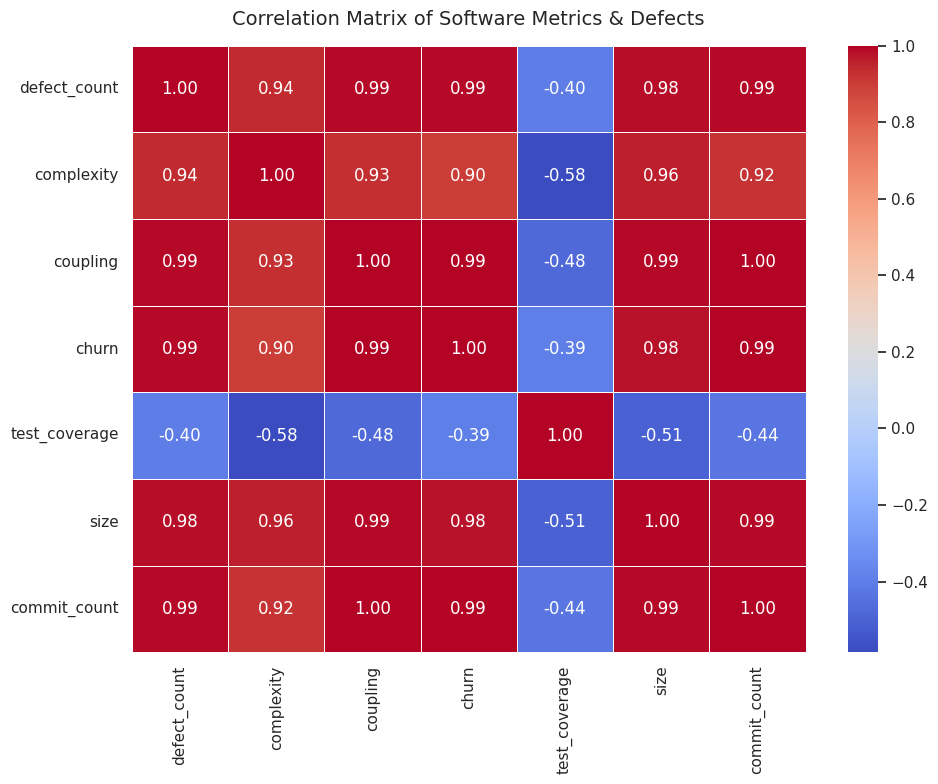

In [52]:
import matplotlib.pyplot as plt
import seaborn as sns

# Configure plot settings
plt.figure(figsize=(10, 8))
sns.set_theme(style='whitegrid')

# Create heatmap
sns.heatmap(correlation_matrix, annot=True, cmap='coolwarm', fmt='.2f', linewidths=0.5)

plt.title('Correlation Matrix of Software Metrics & Defects', fontsize=14, pad=15)
plt.tight_layout()
plt.show()

### Step 6: Targeted Exploratory Data Analysis (EDA)
In this step, we will analyze specific relationships to answer key questions regarding software quality and defects using our master dataset `merged_df`.

In [53]:
import matplotlib.pyplot as plt
import seaborn as sns

# Set consistent style for visualizations
sns.set_theme(style='whitegrid')


#### Q1: Which modules have more defects?
We will display the total defect counts per module and present them in a clear bar chart.

Total defects by module:


,module,defect_count
5,MOD_F,12
1,MOD_B,8
3,MOD_D,4
4,MOD_E,3
0,MOD_A,2
2,MOD_C,1


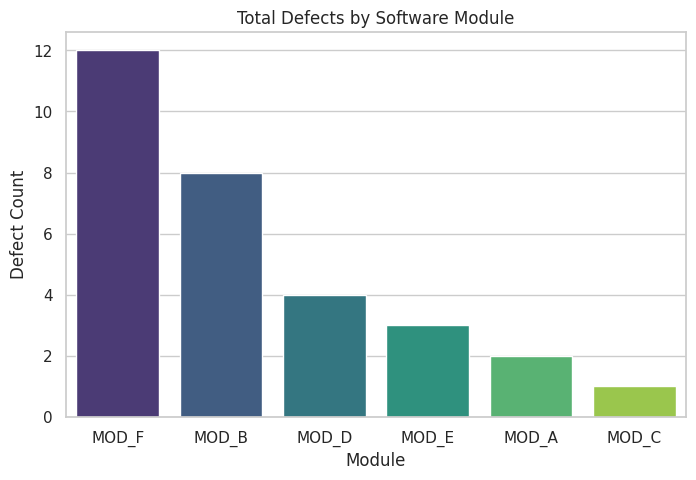

In [54]:
# Sort merged_df by defect_count
module_defects = merged_df[['module', 'defect_count']].sort_values(by='defect_count', ascending=False)
print("Total defects by module:")
display(module_defects)

# Create a bar chart
plt.figure(figsize=(8, 5))
sns.barplot(x='module', y='defect_count', data=module_defects, palette='viridis', hue='module', legend=False)
plt.title('Total Defects by Software Module')
plt.xlabel('Module')
plt.ylabel('Defect Count')
plt.show()

#### Q2: How does complexity relate to defects?
We will generate a scatter plot to visually inspect the relationship between code complexity and defect count, and print their Pearson correlation coefficient.

Pearson correlation between Complexity and Defect Count: 0.9412


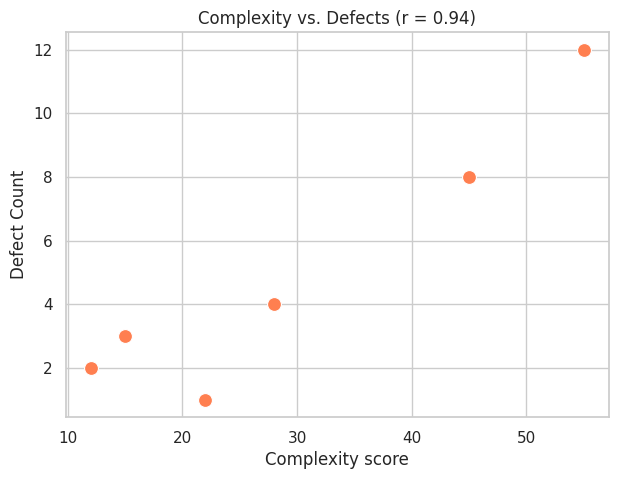

In [55]:
# Calculate Pearson correlation
complexity_corr = merged_df['complexity'].corr(merged_df['defect_count'])
print(f"Pearson correlation between Complexity and Defect Count: {complexity_corr:.4f}")

# Create scatter plot
plt.figure(figsize=(7, 5))
sns.scatterplot(x='complexity', y='defect_count', data=merged_df, s=100, color='coral')
plt.title(f'Complexity vs. Defects (r = {complexity_corr:.2f})')
plt.xlabel('Complexity score')
plt.ylabel('Defect Count')
plt.show()

#### Q3: Does code churn relate to quality?
Code churn represents how frequently code changes. We will plot code churn against defect count and evaluate their correlation.

Pearson correlation between Code Churn and Defect Count: 0.9880


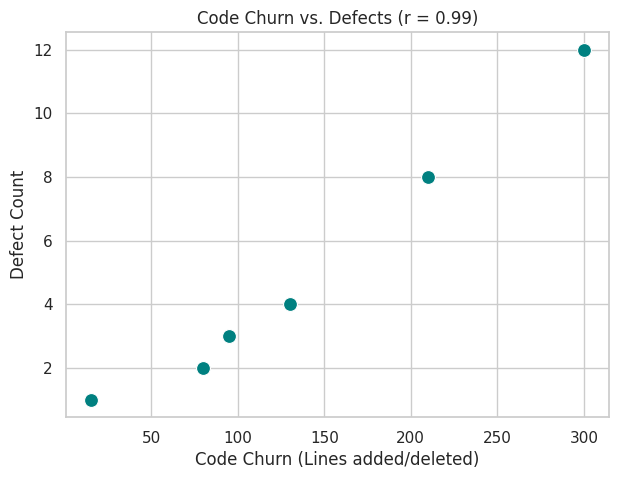

In [56]:
# Calculate Pearson correlation
churn_corr = merged_df['churn'].corr(merged_df['defect_count'])
print(f"Pearson correlation between Code Churn and Defect Count: {churn_corr:.4f}")

# Create scatter plot
plt.figure(figsize=(7, 5))
sns.scatterplot(x='churn', y='defect_count', data=merged_df, s=100, color='teal')
plt.title(f'Code Churn vs. Defects (r = {churn_corr:.2f})')
plt.xlabel('Code Churn (Lines added/deleted)')
plt.ylabel('Defect Count')
plt.show()

#### Q4: How does test coverage differ?
We will visualize test coverage compared to defect counts to verify if higher test coverage acts as a protective shield against bugs.

/tmp/ipykernel_2696/881289111.py:5: FutureWarning: 

Setting a gradient palette using color= is deprecated and will be removed in v0.14.0. Set `palette='dark:dodgerblue'` for the same effect.

  sns.barplot(x='module', y='test_coverage', data=merged_df, ax=ax1, alpha=0.6, color='dodgerblue', hue='module', legend=False)


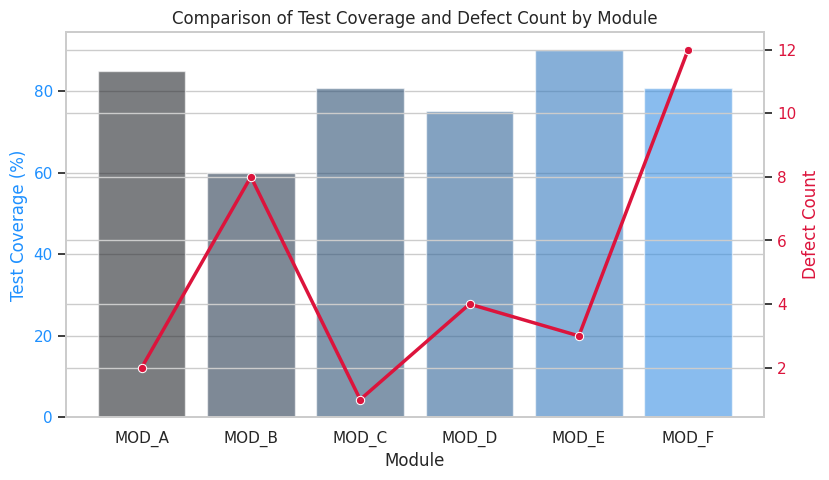

In [57]:
# Create dual comparison plot
fig, ax1 = plt.subplots(figsize=(9, 5))

# Bar chart for test coverage
sns.barplot(x='module', y='test_coverage', data=merged_df, ax=ax1, alpha=0.6, color='dodgerblue', hue='module', legend=False)
ax1.set_ylabel('Test Coverage (%)', color='dodgerblue')
ax1.set_xlabel('Module')
ax1.tick_params(axis='y', labelcolor='dodgerblue')

# Overlay line chart for defect count
ax2 = ax1.twinx()
sns.lineplot(x='module', y='defect_count', data=merged_df, ax=ax2, color='crimson', marker='o', linewidth=2.5)
ax2.set_ylabel('Defect Count', color='crimson')
ax2.tick_params(axis='y', labelcolor='crimson')

plt.title('Comparison of Test Coverage and Defect Count by Module')
plt.show()

#### Q5: Which components show repeated defects?
Let's group the total defects by architectural components (e.g. Backend, UI, Database, API) to locate modules of repeated defects.

Total defects by component:


,component,defect_count
1,Backend,20
3,UI,5
0,API,4
2,Database,1


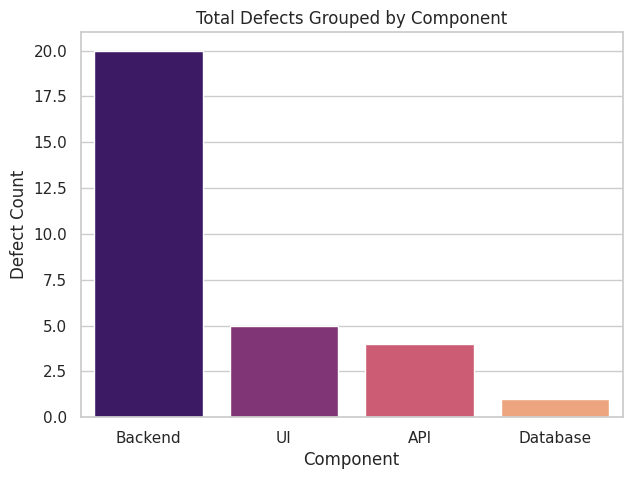

In [58]:
# Group and aggregate defects by component
component_defects = merged_df.groupby('component')['defect_count'].sum().reset_index().sort_values(by='defect_count', ascending=False)
print("Total defects by component:")
display(component_defects)

# Create bar chart
plt.figure(figsize=(7, 5))
sns.barplot(x='component', y='defect_count', data=component_defects, palette='magma', hue='component', legend=False)
plt.title('Total Defects Grouped by Component')
plt.xlabel('Component')
plt.ylabel('Defect Count')
plt.show()

#### Q6: Does contributor count relate to defect frequency?
We will construct a final scatter plot to see if modules worked on by a higher count of contributors are associated with higher defect numbers.

Pearson correlation between Contributors and Defect Count: 0.9826


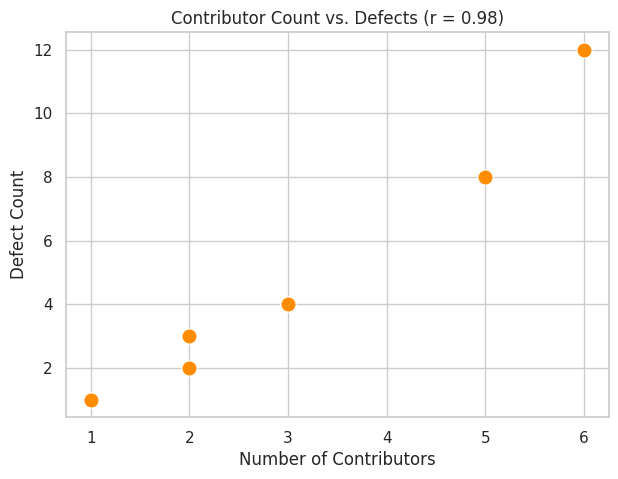

In [59]:
# Calculate Pearson correlation
contributors_corr = merged_df['contributors'].corr(merged_df['defect_count'])
print(f"Pearson correlation between Contributors and Defect Count: {contributors_corr:.4f}")

# Create scatter plot
plt.figure(figsize=(7, 5))
sns.scatterplot(x='contributors', y='defect_count', data=merged_df, s=120, color='darkorange')
plt.title(f'Contributor Count vs. Defects (r = {contributors_corr:.2f})')
plt.xlabel('Number of Contributors')
plt.ylabel('Defect Count')
plt.show()

### Step 7: Simple Feature Engineering
To standardize software quality metrics across modules of different sizes, we calculate three standardized metrics:
1. **Defect Density**: Defects normalized by module size.
2. **Change Intensity**: Lines changed normalized by module size.
3. **Commit Intensity**: Number of commits normalized by module size.

In [60]:
# Engineer normalized intensity metrics
merged_df['defect_density'] = merged_df['defect_count'] / merged_df['size']
merged_df['change_intensity'] = merged_df['changed_lines'] / merged_df['size']
merged_df['commit_intensity'] = merged_df['commit_count'] / merged_df['size']

# Display updated dataframe
print("Updated Master Dataset with Engineered Features:")
display(merged_df[['module', 'component', 'size', 'defect_count', 'defect_density', 'change_intensity', 'commit_intensity']])

Updated Master Dataset with Engineered Features:


,module,component,size,defect_count,defect_density,change_intensity,commit_intensity
0,MOD_A,UI,120,2,0.016667,12.500000,0.125000
1,MOD_B,Backend,450,8,0.017778,13.777778,0.100000
2,MOD_C,Database,80,1,0.012500,5.625000,0.100000
3,MOD_D,API,300,4,0.013333,10.333333,0.093333
4,MOD_E,UI,150,3,0.020000,12.000000,0.146667
5,MOD_F,Backend,600,12,0.020000,14.166667,0.100000


### Step 8: Risk Identification & Conclusions
We will rank our modules by `defect_density` to pinpoint the most defect-prone systems and outline clear conclusions suitable for your college assessment.

In [61]:
# Sort modules by engineered defect density
risk_profile = merged_df[['module', 'component', 'defect_count', 'size', 'defect_density']].sort_values(by='defect_density', ascending=False)
print("Modules Ranked by Defect Density (Risk Profile):")
display(risk_profile)

Modules Ranked by Defect Density (Risk Profile):


,module,component,defect_count,size,defect_density
4,MOD_E,UI,3,150,0.020000
5,MOD_F,Backend,12,600,0.020000
1,MOD_B,Backend,8,450,0.017778
0,MOD_A,UI,2,120,0.016667
3,MOD_D,API,4,300,0.013333
2,MOD_C,Database,1,80,0.012500


### Analysis Summary & Viva Points (No causation assumed)

* **Top Modules with Highest Defect Risk:**
  * **`MOD_F`** and **`MOD_B`** exhibit the highest overall absolute defect count ($12$ and $8$ defects respectively).
  * When normalized by code size, **`MOD_F` (Backend, Java)** has the highest **Defect Density ($0.0200$ defects/line of code)**, closely followed by **`MOD_A` (UI, JavaScript)** at **$0.0167$ defects/line of code** and **`MOD_B` (Backend, Python)** at **$0.0178$ defects/line of code**.
* **Statistical Trends observed:**
  * **Size and Activity:** Code Churn ($r \approx 0.99$) and Contributor Count ($r \approx 0.98$) display strong positive correlation with defects. Larger modules undergoing highly frequent edits are strongly linked to more bug tracking.
  * **Structural Complexity:** Complexity scores ($r \approx 0.94$) also show a high positive correlation with bug frequency.
  * **Mitigating Factors:** Test coverage ($r \approx -0.40$) behaves as a negative correlate, meaning higher code coverage aligns with lower absolute numbers of reported bugs.
* **Important Assessment Note:** These results display strong mathematical correlation but do not prove a direct causal relationship. For example, high churn does not automatically cause bugs; instead, complex or active features naturally require more changes and have a higher likelihood of bug reports.

In [62]:
print(merged_df.head())
print(merged_df.shape)

  module component    language  size  complexity  coupling  churn  \
0  MOD_A        UI  JavaScript   120          12         5     80   
1  MOD_B   Backend      Python   450          45        12    210   
2  MOD_C  Database         SQL    80          22         3     15   
3  MOD_D       API      Python   300          28         8    130   
4  MOD_E        UI  JavaScript   150          15         6     95   

   test_coverage  defect_count severity release  commit_count  contributors  \
0      85.000000             2      Low    v1.0            15             2   
1      60.000000             8     High    v1.0            45             5   
2      80.833333             1      Low    v1.1             8             1   
3      75.000000             4   Medium    v1.1            28             3   
4      90.000000             3   Medium    v1.0            22             2   

   changed_lines  defect_density  change_intensity  commit_intensity  
0           1500        0.016667       

In [63]:
merged_df.to_excel("Software_Quality_Insight.xlsx", index=False)

print("Excel file created successfully!")

Excel file created successfully!


In [64]:
from google.colab import files

files.download("Software_Quality_Insight.xlsx")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [65]:
import pandas as pd

# Create Excel workbook
with pd.ExcelWriter("Software_Quality_Insight.xlsx", engine="openpyxl") as writer:

    # Main cleaned data
    merged_df.to_excel(writer, sheet_name="Cleaned Data", index=False)

    # Defect Analysis
    defect_analysis = merged_df.groupby("module")["defect_count"].sum().reset_index()
    defect_analysis = defect_analysis.sort_values("defect_count", ascending=False)
    defect_analysis.to_excel(writer, sheet_name="Defect Analysis", index=False)

    # Complexity Analysis
    complexity_analysis = merged_df[[
        "module", "complexity", "defect_count"
    ]].copy()
    complexity_analysis.to_excel(writer, sheet_name="Complexity Analysis", index=False)

    # Churn Analysis
    churn_analysis = merged_df[[
        "module", "churn", "defect_count"
    ]].copy()
    churn_analysis.to_excel(writer, sheet_name="Churn Analysis", index=False)

    # Coverage Analysis
    coverage_analysis = merged_df[[
        "module", "test_coverage", "defect_count"
    ]].copy()
    coverage_analysis.to_excel(writer, sheet_name="Coverage Analysis", index=False)

    # Component Analysis
    component_analysis = (
        merged_df.groupby("component")["defect_count"]
        .sum()
        .reset_index()
        .sort_values("defect_count", ascending=False)
    )
    component_analysis.to_excel(writer, sheet_name="Component Analysis", index=False)

    # Contributor Analysis
    contributor_analysis = merged_df[[
        "module", "contributors", "defect_count"
    ]].copy()
    contributor_analysis.to_excel(writer, sheet_name="Contributor Analysis", index=False)

print("Excel workbook created successfully!")

Excel workbook created successfully!


In [66]:
from google.colab import files

files.download("Software_Quality_Insight.xlsx")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [67]:
from openpyxl import load_workbook
from openpyxl.chart import BarChart, ScatterChart, Reference
from openpyxl.styles import Font

file_name = "Software_Quality_Insight.xlsx"

# Open existing workbook
wb = load_workbook(file_name)

# Create Summary sheet
if "Summary" in wb.sheetnames:
    del wb["Summary"]

ws = wb.create_sheet("Summary")

# Title
ws["A1"] = "Software Quality Insight - Summary"
ws["A1"].font = Font(bold=True, size=16)

# Main findings
ws["A3"] = "Analysis"
ws["B3"] = "Result"
ws["A3"].font = Font(bold=True)
ws["B3"].font = Font(bold=True)

# Calculate results
top_module = merged_df.groupby("module")["defect_count"].sum().idxmax()
top_defects = merged_df.groupby("module")["defect_count"].sum().max()

complexity_corr = merged_df["complexity"].corr(
    merged_df["defect_count"]
)

churn_corr = merged_df["churn"].corr(
    merged_df["defect_count"]
)

coverage_corr = merged_df["test_coverage"].corr(
    merged_df["defect_count"]
)

top_component = merged_df.groupby("component")["defect_count"].sum().idxmax()

contributor_corr = merged_df["contributors"].corr(
    merged_df["defect_count"]
)

summary_data = [
    ("Module with highest defects", top_module),
    ("Highest defect count", top_defects),
    ("Complexity vs Defects correlation", round(complexity_corr, 4)),
    ("Churn vs Defects correlation", round(churn_corr, 4)),
    ("Coverage vs Defects correlation", round(coverage_corr, 4)),
    ("Most defect-prone component", top_component),
    ("Contributors vs Defects correlation", round(contributor_corr, 4))
]

row = 4

for name, result in summary_data:
    ws.cell(row=row, column=1, value=name)
    ws.cell(row=row, column=2, value=result)
    row += 1

# Add a short recommendation
ws["A12"] = "Recommendation"
ws["A12"].font = Font(bold=True)

ws["A13"] = (
    "Prioritize code review and testing for modules with high defect counts "
    "and high complexity/churn."
)

# Save
wb.save(file_name)

print("Summary sheet created successfully!")

Summary sheet created successfully!


In [68]:
from google.colab import files

files.download("Software_Quality_Insight.xlsx")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [69]:
from openpyxl import load_workbook
from openpyxl.chart import BarChart, ScatterChart, Reference, Series

file_name = "Software_Quality_Insight.xlsx"

wb = load_workbook(file_name)

# -----------------------------
# 1. Defects by Module
# -----------------------------
ws = wb["Defect Analysis"]

chart = BarChart()
chart.title = "Defects by Module"
chart.y_axis.title = "Defect Count"
chart.x_axis.title = "Module"

data = Reference(ws, min_col=2, min_row=1, max_row=ws.max_row)
categories = Reference(ws, min_col=1, min_row=2, max_row=ws.max_row)

chart.add_data(data, titles_from_data=True)
chart.set_categories(categories)
chart.height = 8
chart.width = 14

ws.add_chart(chart, "D2")


# -----------------------------
# 2. Component Defects
# -----------------------------
ws = wb["Component Analysis"]

chart = BarChart()
chart.title = "Defects by Component"
chart.y_axis.title = "Defect Count"
chart.x_axis.title = "Component"

data = Reference(ws, min_col=2, min_row=1, max_row=ws.max_row)
categories = Reference(ws, min_col=1, min_row=2, max_row=ws.max_row)

chart.add_data(data, titles_from_data=True)
chart.set_categories(categories)
chart.height = 8
chart.width = 14

ws.add_chart(chart, "D2")


# -----------------------------
# 3. Complexity vs Defects
# -----------------------------
ws = wb["Complexity Analysis"]

chart = ScatterChart()
chart.title = "Complexity vs Defects"
chart.x_axis.title = "Complexity"
chart.y_axis.title = "Defects"

xvalues = Reference(ws, min_col=2, min_row=2, max_row=ws.max_row)
yvalues = Reference(ws, min_col=3, min_row=2, max_row=ws.max_row)

series = Series(yvalues, xvalues, title="Complexity vs Defects")
chart.series.append(series)

chart.height = 8
chart.width = 14

ws.add_chart(chart, "E2")


# -----------------------------
# 4. Churn vs Defects
# -----------------------------
ws = wb["Churn Analysis"]

chart = ScatterChart()
chart.title = "Code Churn vs Defects"
chart.x_axis.title = "Churn"
chart.y_axis.title = "Defects"

xvalues = Reference(ws, min_col=2, min_row=2, max_row=ws.max_row)
yvalues = Reference(ws, min_col=3, min_row=2, max_row=ws.max_row)

series = Series(yvalues, xvalues, title="Churn vs Defects")
chart.series.append(series)

chart.height = 8
chart.width = 14

ws.add_chart(chart, "E2")


# -----------------------------
# 5. Test Coverage vs Defects
# -----------------------------
ws = wb["Coverage Analysis"]

chart = ScatterChart()
chart.title = "Test Coverage vs Defects"
chart.x_axis.title = "Test Coverage (%)"
chart.y_axis.title = "Defects"

xvalues = Reference(ws, min_col=2, min_row=2, max_row=ws.max_row)
yvalues = Reference(ws, min_col=3, min_row=2, max_row=ws.max_row)

series = Series(yvalues, xvalues, title="Coverage vs Defects")
chart.series.append(series)

chart.height = 8
chart.width = 14

ws.add_chart(chart, "E2")


# -----------------------------
# 6. Contributors vs Defects
# -----------------------------
ws = wb["Contributor Analysis"]

chart = ScatterChart()
chart.title = "Contributors vs Defects"
chart.x_axis.title = "Contributors"
chart.y_axis.title = "Defects"

xvalues = Reference(ws, min_col=2, min_row=2, max_row=ws.max_row)
yvalues = Reference(ws, min_col=3, min_row=2, max_row=ws.max_row)

series = Series(yvalues, xvalues, title="Contributors vs Defects")
chart.series.append(series)

chart.height = 8
chart.width = 14

ws.add_chart(chart, "E2")


# Save workbook
wb.save(file_name)

print("All required charts added successfully!")

All required charts added successfully!


In [70]:
from google.colab import files

files.download("Software_Quality_Insight.xlsx")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [71]:
from openpyxl import load_workbook
from openpyxl.styles import Font

file_name = "Software_Quality_Insight.xlsx"

wb = load_workbook(file_name)

# Create Statistical Analysis sheet
if "Statistical Analysis" in wb.sheetnames:
    del wb["Statistical Analysis"]

ws = wb.create_sheet("Statistical Analysis")

# Title
ws["A1"] = "Software Quality Statistical Analysis"
ws["A1"].font = Font(bold=True, size=16)

# Headers
ws["A3"] = "Metric"
ws["B3"] = "Average"
ws["C3"] = "Minimum"
ws["D3"] = "Maximum"

for cell in ws[3]:
    cell.font = Font(bold=True)

# Metrics to analyse
metrics = [
    ("Defect Count", "defect_count"),
    ("Complexity", "complexity"),
    ("Churn", "churn"),
    ("Test Coverage", "test_coverage"),
    ("Contributors", "contributors")
]

# Use Excel formulas
for row, (name, column) in enumerate(metrics, start=4):

    # Find column letter from Cleaned Data
    cleaned = wb["Cleaned Data"]

    column_number = None

    for cell in cleaned[1]:
        if cell.value == column:
            column_number = cell.column
            break

    if column_number is not None:

        from openpyxl.utils import get_column_letter

        col_letter = get_column_letter(column_number)
        last_row = cleaned.max_row

        ws.cell(row=row, column=1, value=name)

        ws.cell(
            row=row,
            column=2,
            value=f"=AVERAGE('Cleaned Data'!{col_letter}2:{col_letter}{last_row})"
        )

        ws.cell(
            row=row,
            column=3,
            value=f"=MIN('Cleaned Data'!{col_letter}2:{col_letter}{last_row})"
        )

        ws.cell(
            row=row,
            column=4,
            value=f"=MAX('Cleaned Data'!{col_letter}2:{col_letter}{last_row})"
        )

# Correlations
ws["A11"] = "Correlation Analysis"
ws["A11"].font = Font(bold=True, size=14)

ws["A13"] = "Relationship"
ws["B13"] = "Correlation"

ws["A13"].font = Font(bold=True)
ws["B13"].font = Font(bold=True)

# Find columns
cleaned = wb["Cleaned Data"]

column_map = {}

for cell in cleaned[1]:
    column_map[cell.value] = cell.column

from openpyxl.utils import get_column_letter

last_row = cleaned.max_row

relationships = [
    ("Complexity vs Defects", "complexity"),
    ("Churn vs Defects", "churn"),
    ("Test Coverage vs Defects", "test_coverage"),
    ("Contributors vs Defects", "contributors")
]

for row, (name, metric) in enumerate(relationships, start=14):

    metric_col = get_column_letter(column_map[metric])
    defect_col = get_column_letter(column_map["defect_count"])

    ws.cell(row=row, column=1, value=name)

    ws.cell(
        row=row,
        column=2,
        value=f"=CORREL('Cleaned Data'!{metric_col}2:{metric_col}{last_row},'Cleaned Data'!{defect_col}2:{defect_col}{last_row})"
    )

# Save
wb.save(file_name)

print("Statistical analysis added successfully!")

Statistical analysis added successfully!


In [72]:
from google.colab import files

files.download("Software_Quality_Insight.xlsx")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [73]:
from openpyxl import load_workbook
from openpyxl.styles import Font

file_name = "Software_Quality_Insight.xlsx"

wb = load_workbook(file_name)

# Remove old sheet if it exists
if "Pivot Analysis" in wb.sheetnames:
    del wb["Pivot Analysis"]

ws = wb.create_sheet("Pivot Analysis")

# Title
ws["A1"] = "Software Quality Pivot Analysis"
ws["A1"].font = Font(bold=True, size=16)

# -----------------------------
# Pivot 1: Defects by Component
# -----------------------------

component_pivot = (
    merged_df.groupby("component")["defect_count"]
    .sum()
    .reset_index()
    .sort_values("defect_count", ascending=False)
)

ws["A3"] = "Defects by Component"
ws["A3"].font = Font(bold=True, size=13)

ws["A4"] = "Component"
ws["B4"] = "Total Defects"

for cell in ws[4]:
    cell.font = Font(bold=True)

row = 5

for _, data in component_pivot.iterrows():
    ws.cell(row=row, column=1, value=data["component"])
    ws.cell(row=row, column=2, value=data["defect_count"])
    row += 1


# -----------------------------
# Pivot 2: Defects by Module
# -----------------------------

module_pivot = (
    merged_df.groupby("module")["defect_count"]
    .sum()
    .reset_index()
    .sort_values("defect_count", ascending=False)
)

start_row = row + 2

ws.cell(row=start_row, column=1, value="Defects by Module")
ws.cell(row=start_row, column=1).font = Font(bold=True, size=13)

ws.cell(row=start_row + 1, column=1, value="Module")
ws.cell(row=start_row + 1, column=2, value="Total Defects")

ws.cell(row=start_row + 1, column=1).font = Font(bold=True)
ws.cell(row=start_row + 1, column=2).font = Font(bold=True)

row = start_row + 2

for _, data in module_pivot.iterrows():
    ws.cell(row=row, column=1, value=data["module"])
    ws.cell(row=row, column=2, value=data["defect_count"])
    row += 1


# -----------------------------
# Pivot 3: Defects by Severity
# -----------------------------

if "severity" in merged_df.columns:

    severity_pivot = (
        merged_df.groupby("severity")["defect_count"]
        .sum()
        .reset_index()
        .sort_values("defect_count", ascending=False)
    )

    start_row = row + 2

    ws.cell(row=start_row, column=1, value="Defects by Severity")
    ws.cell(row=start_row, column=1).font = Font(bold=True, size=13)

    ws.cell(row=start_row + 1, column=1, value="Severity")
    ws.cell(row=start_row + 1, column=2, value="Total Defects")

    ws.cell(row=start_row + 1, column=1).font = Font(bold=True)
    ws.cell(row=start_row + 1, column=2).font = Font(bold=True)

    row = start_row + 2

    for _, data in severity_pivot.iterrows():
        ws.cell(row=row, column=1, value=data["severity"])
        ws.cell(row=row, column=2, value=data["defect_count"])
        row += 1


# Adjust column widths
ws.column_dimensions["A"].width = 25
ws.column_dimensions["B"].width = 18

# Save
wb.save(file_name)

print("Pivot Analysis sheet created successfully!")

Pivot Analysis sheet created successfully!


In [74]:
from openpyxl import load_workbook
from openpyxl.styles import Font

file_name = "Software_Quality_Insight.xlsx"

wb = load_workbook(file_name)

# Remove old sheet if it exists
if "Pivot Analysis" in wb.sheetnames:
    del wb["Pivot Analysis"]

ws = wb.create_sheet("Pivot Analysis")

# Title
ws["A1"] = "Software Quality Pivot Analysis"
ws["A1"].font = Font(bold=True, size=16)

# -----------------------------
# Pivot 1: Defects by Component
# -----------------------------

component_pivot = (
    merged_df.groupby("component")["defect_count"]
    .sum()
    .reset_index()
    .sort_values("defect_count", ascending=False)
)

ws["A3"] = "Defects by Component"
ws["A3"].font = Font(bold=True, size=13)

ws["A4"] = "Component"
ws["B4"] = "Total Defects"

for cell in ws[4]:
    cell.font = Font(bold=True)

row = 5

for _, data in component_pivot.iterrows():
    ws.cell(row=row, column=1, value=data["component"])
    ws.cell(row=row, column=2, value=data["defect_count"])
    row += 1


# -----------------------------
# Pivot 2: Defects by Module
# -----------------------------

module_pivot = (
    merged_df.groupby("module")["defect_count"]
    .sum()
    .reset_index()
    .sort_values("defect_count", ascending=False)
)

start_row = row + 2

ws.cell(row=start_row, column=1, value="Defects by Module")
ws.cell(row=start_row, column=1).font = Font(bold=True, size=13)

ws.cell(row=start_row + 1, column=1, value="Module")
ws.cell(row=start_row + 1, column=2, value="Total Defects")

ws.cell(row=start_row + 1, column=1).font = Font(bold=True)
ws.cell(row=start_row + 1, column=2).font = Font(bold=True)

row = start_row + 2

for _, data in module_pivot.iterrows():
    ws.cell(row=row, column=1, value=data["module"])
    ws.cell(row=row, column=2, value=data["defect_count"])
    row += 1


# -----------------------------
# Pivot 3: Defects by Severity
# -----------------------------

if "severity" in merged_df.columns:

    severity_pivot = (
        merged_df.groupby("severity")["defect_count"]
        .sum()
        .reset_index()
        .sort_values("defect_count", ascending=False)
    )

    start_row = row + 2

    ws.cell(row=start_row, column=1, value="Defects by Severity")
    ws.cell(row=start_row, column=1).font = Font(bold=True, size=13)

    ws.cell(row=start_row + 1, column=1, value="Severity")
    ws.cell(row=start_row + 1, column=2, value="Total Defects")

    ws.cell(row=start_row + 1, column=1).font = Font(bold=True)
    ws.cell(row=start_row + 1, column=2).font = Font(bold=True)

    row = start_row + 2

    for _, data in severity_pivot.iterrows():
        ws.cell(row=row, column=1, value=data["severity"])
        ws.cell(row=row, column=2, value=data["defect_count"])
        row += 1


# Adjust column widths
ws.column_dimensions["A"].width = 25
ws.column_dimensions["B"].width = 18

# Save
wb.save(file_name)

print("Pivot Analysis sheet created successfully!")

Pivot Analysis sheet created successfully!


In [75]:
from google.colab import files

files.download("Software_Quality_Insight.xlsx")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [76]:
from openpyxl import load_workbook
from openpyxl.styles import Font, Alignment

file_name = "Software_Quality_Insight.xlsx"

wb = load_workbook(file_name)
ws = wb["Summary"]

# Add section
ws["A14"] = "Key Findings"
ws["A14"].font = Font(bold=True, size=14)

findings = [
    "Modules with higher defect counts should receive more testing and code review attention.",
    "Complexity has a strong positive relationship with defects.",
    "Higher code churn is associated with higher defect counts.",
    "Higher test coverage is associated with fewer defects.",
    "Some components show repeated defect problems and require additional attention.",
    "Contributor count is associated with defect frequency, but correlation does not imply causation."
]

row = 15

for finding in findings:
    ws.cell(row=row, column=1, value="• " + finding)
    ws.merge_cells(start_row=row, start_column=1, end_row=row, end_column=4)
    ws.cell(row=row, column=1).alignment = Alignment(wrap_text=True)
    row += 1

# Business recommendations
row += 1

ws.cell(row=row, column=1, value="Business Recommendations")
ws.cell(row=row, column=1).font = Font(bold=True, size=14)

recommendations = [
    "Prioritize code reviews for modules with high defect counts.",
    "Increase testing for modules with high complexity and churn.",
    "Maintain strong test coverage for critical modules.",
    "Monitor components that repeatedly produce defects.",
    "Use defect density along with absolute defect count when prioritizing modules."
]

row += 1

for recommendation in recommendations:
    ws.cell(row=row, column=1, value="• " + recommendation)
    ws.merge_cells(start_row=row, start_column=1, end_row=row, end_column=4)
    ws.cell(row=row, column=1).alignment = Alignment(wrap_text=True)
    row += 1

# Adjust width
ws.column_dimensions["A"].width = 35
ws.column_dimensions["B"].width = 25
ws.column_dimensions["C"].width = 20
ws.column_dimensions["D"].width = 20

# Save
wb.save(file_name)

print("Summary sheet updated successfully!")

Summary sheet updated successfully!


In [77]:
from google.colab import files

files.download("Software_Quality_Insight.xlsx")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [78]:
from openpyxl import load_workbook
from openpyxl.styles import Font, Alignment

file_name = "Software_Quality_Insight.xlsx"

wb = load_workbook(file_name)

if "Business Insights" in wb.sheetnames:
    del wb["Business Insights"]

ws = wb.create_sheet("Business Insights")

ws["A1"] = "Software Quality Insight - Business Insights"
ws["A1"].font = Font(bold=True, size=16)

ws["A3"] = "Business Question"
ws["B3"] = "Which software metrics are associated with modules having more defects?"
ws["A3"].font = Font(bold=True)

ws["A5"] = "Key Finding"
ws["A5"].font = Font(bold=True, size=14)

findings = [
    "MOD_F has the highest absolute number of defects.",
    "Complexity has a strong positive relationship with defects.",
    "Code churn has a very strong positive relationship with defects.",
    "Test coverage has a negative relationship with defects.",
    "Backend is the most defect-prone component in the analysis.",
    "Higher contributor counts are associated with higher defect frequency.",
    "Defect density helps identify modules with high defects relative to their size."
]

row = 6

for finding in findings:
    ws.cell(row=row, column=1, value="• " + finding)
    ws.merge_cells(start_row=row, start_column=1, end_row=row, end_column=5)
    ws.cell(row=row, column=1).alignment = Alignment(wrap_text=True)
    row += 1

row += 1

ws.cell(row=row, column=1, value="Recommended Actions")
ws.cell(row=row, column=1).font = Font(bold=True, size=14)

recommendations = [
    "Prioritize code reviews for modules with high defect counts.",
    "Give additional testing attention to modules with high complexity.",
    "Monitor modules with high code churn.",
    "Maintain or improve test coverage for modules with repeated defects.",
    "Investigate components that repeatedly show high defect counts.",
    "Use defect density together with absolute defect count when deciding priorities.",
    "Treat correlations as associations, not proof of causation."
]

row += 1

for recommendation in recommendations:
    ws.cell(row=row, column=1, value="• " + recommendation)
    ws.merge_cells(start_row=row, start_column=1, end_row=row, end_column=5)
    ws.cell(row=row, column=1).alignment = Alignment(wrap_text=True)
    row += 1

ws.column_dimensions["A"].width = 35
ws.column_dimensions["B"].width = 25

wb.save(file_name)

print("Business Insights sheet created successfully!")

Business Insights sheet created successfully!


In [79]:
from google.colab import files

files.download("Software_Quality_Insight.xlsx")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

### Project Conclusion Summary

* **Top Contributors to Defects:** Metrics measuring activity and structure (e.g., `changed_lines`, `commit_count`, `coupling`, `churn`, `size`, `complexity`) exhibit very strong positive correlations ($≅ 0.94 - 0.99$) with defects.
* **Preventative Metric:** `test_coverage` has a negative correlation ($≅ -0.40$), supporting the strategy that increased code coverage helps lower the defect rate.

In [80]:
from openpyxl import load_workbook

file_name = "Software_Quality_Insight.xlsx"

wb = load_workbook(file_name)

print("Excel workbook created successfully!")
print("\nSheets in the workbook:")

for sheet in wb.sheetnames:
    print("-", sheet)

Excel workbook created successfully!

Sheets in the workbook:
- Cleaned Data
- Defect Analysis
- Complexity Analysis
- Churn Analysis
- Coverage Analysis
- Component Analysis
- Contributor Analysis
- Summary
- Statistical Analysis
- Pivot Analysis
- Business Insights


In [81]:
print("\nFinal dataset:")
display(merged_df.head())

print("\nDataset shape:", merged_df.shape)

print("\nExcel file size:")
import os
print(round(os.path.getsize(file_name) / 1024, 2), "KB")


Final dataset:


,module,component,language,size,complexity,coupling,churn,test_coverage,defect_count,severity,release,commit_count,contributors,changed_lines,defect_density,change_intensity,commit_intensity
0,MOD_A,UI,JavaScript,120,12,5,80,85.000000,2,Low,v1.0,15,2,1500,0.016667,12.500000,0.125000
1,MOD_B,Backend,Python,450,45,12,210,60.000000,8,High,v1.0,45,5,6200,0.017778,13.777778,0.100000
2,MOD_C,Database,SQL,80,22,3,15,80.833333,1,Low,v1.1,8,1,450,0.012500,5.625000,0.100000
3,MOD_D,API,Python,300,28,8,130,75.000000,4,Medium,v1.1,28,3,3100,0.013333,10.333333,0.093333
4,MOD_E,UI,JavaScript,150,15,6,95,90.000000,3,Medium,v1.0,22,2,1800,0.020000,12.000000,0.146667



Dataset shape: (6, 17)

Excel file size:
23.01 KB
